In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [4]:
import json
import sys
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from dask.diagnostics import ProgressBar

sys.path.append("../..")


from src.conversion_energy.demand import (
    normalize_population_data,
    process_population_data,
)
from src.conversion_energy.plots import plot_yearly_mean_boxplot
from src.data_processing.load_data import ClimateModelData
from src.results.analysis import compute_percentage_change
from src.results.plotting import (
    apply_land_mask,
    plot_ensemble_mean,
    plot_ensemble_mean_percentage_change,
    plot_yearly_timeseries_ensemble,
)
from src.utils.constants import (
    EXTENT_BC,
    EXTENT_CH,
    MID_CENTURY_PERIOD,
    NEAR_FUTURE_PERIOD,
    REFERENCE_PERIOD,
)
from src.utils.utils_xarray import sel_extent

sns.set_style("whitegrid", {"grid.color": ".93"})

In [5]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [6]:
extent = {"lat_min": 30, "lat_max": 72.6, "lon_min": -12, "lon_max": 30}
extent_pop = {"lat_min": 29, "lat_max": 76, "lon_min": -11, "lon_max": 31}
extent_pop_ch = {"lat_min": 29, "lat_max": 76, "lon_min": -11, "lon_max": 31}

In [7]:
europe_turbines = ["E-126/7580", "SWT120/3600", "SWT142/3150"]
ch_turbines = ["E-82/2300", "E-92/2350", "V90/2000", "V112/3300"]
climate_scenario = "rcp85"

In [8]:
valid_models = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85",
    "CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1_rcp85",
    "CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85",
    "CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85"
]

In [9]:
# dask.config.set(num_workers=15, scheduler="processes")
dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,  # Spill to disk at 70%
        "distributed.worker.memory.spill": 0.8,  # Start spilling at 80%
        "distributed.worker.memory.pause": 0.9,  # Pause worker at 90%
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",  # Less verbose logs
    }
)

# Europe

##

In [44]:
selected_turbine = europe_turbines[0]

In [45]:
ds_orog_cnrm = sel_extent(
    xr.open_dataset(
        sorted(
            (path_data_temporary / "cordex_processed").glob("CNRM*/regridded/fx/*.nc")
        )[0]
    ),
    extent,
)

## Aggregates

### PV

In [31]:
path_pv = path_energy_europe / "pv"
paths_pv_nc = sorted(path_pv.glob("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_*/pv_agg_*.nc"))

In [36]:
datasets = [xr.open_dataset(p, chunks="auto") for p in paths_pv_nc]
scenarios_datasets = [p.parent.name.split("_")[-1] for p in paths_pv_nc]
var = list(datasets[0].data_vars.keys())[0]

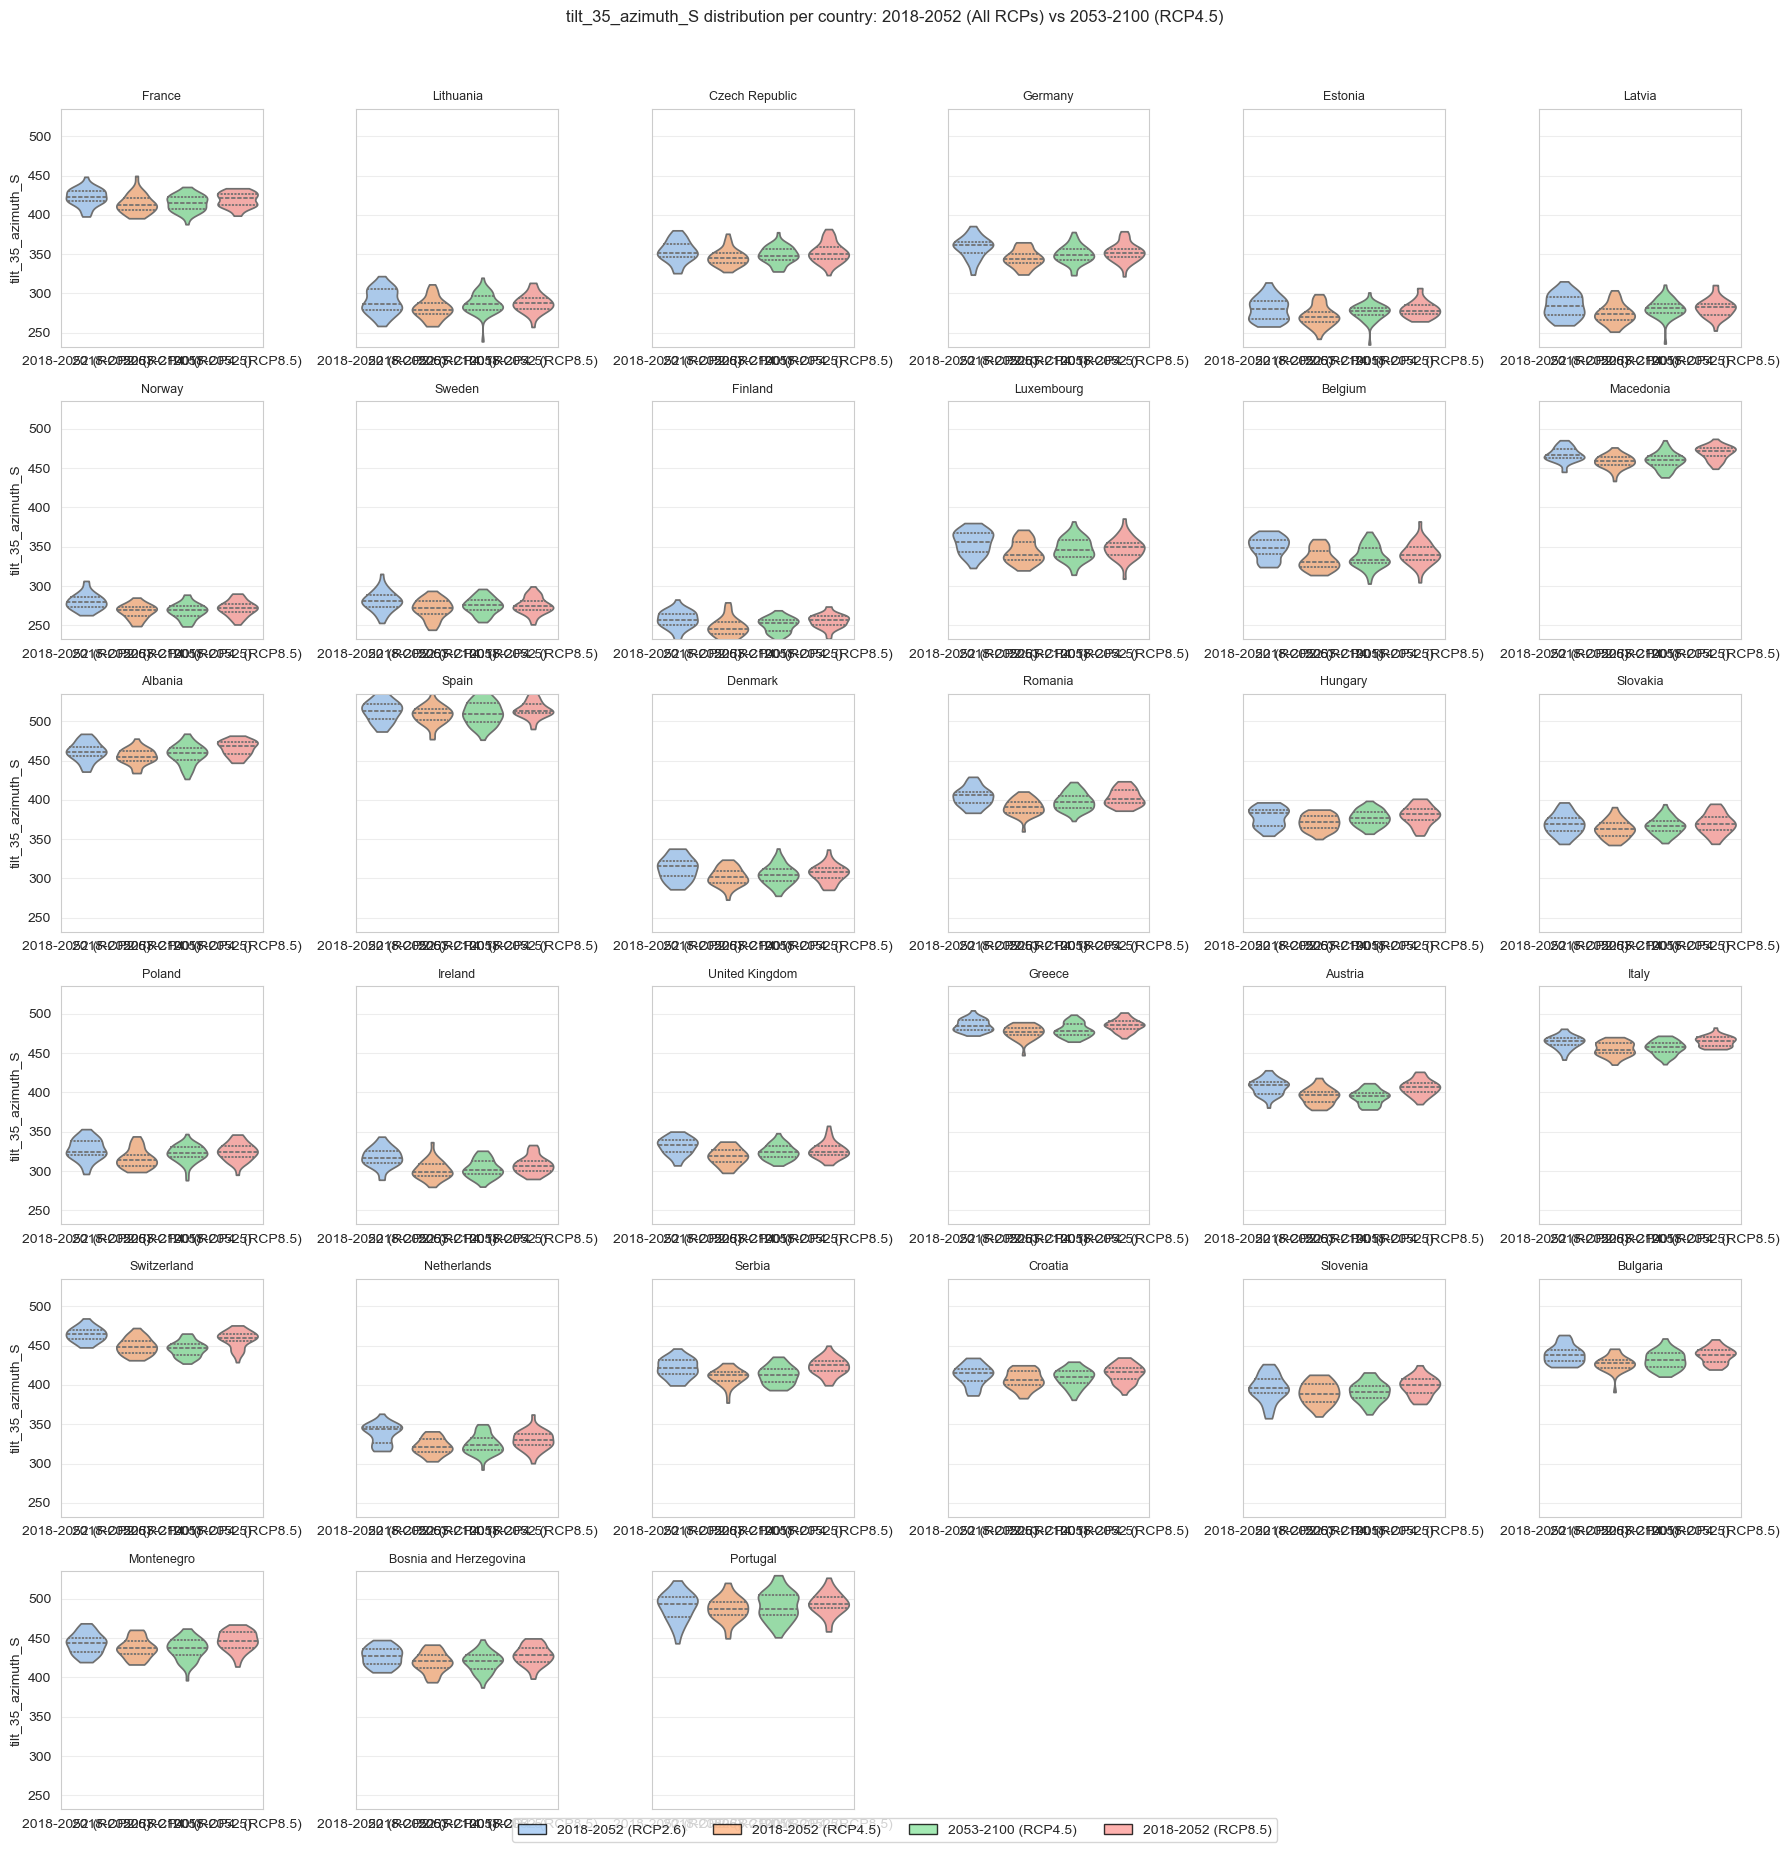

In [24]:
from matplotlib.patches import Patch

# compare datasets[1] periods to the combined full period of datasets[0] + datasets[1]
ds0_annual = datasets[0].resample(time="YE").sum(dim="time")
ds1_annual = datasets[1].resample(time="YE").sum(dim="time")
ds2_annual = datasets[2].resample(time="YE").sum(dim="time")

# convert to dataframes and drop NaNs
df0 = ds0_annual[var].to_dataframe().reset_index().dropna(subset=[var])
df1 = ds1_annual[var].to_dataframe().reset_index().dropna(subset=[var])
df2 = ds2_annual[var].to_dataframe().reset_index().dropna(subset=[var])

# slices from datasets[1]
df1_mid = df1[df1["time"].between("2018-01-01", "2052-12-31")].copy()
df1_mid["period"] = "2018-2052"
df1_late = df1[df1["time"].between("2053-01-01", "2100-12-31")].copy()
df1_late["period"] = "2053-2100"

# combined dataframe for plotting
combined_df = pd.concat([df0, df1_mid, df1_late, df2], ignore_index=True)

# plotting setup
countries_plot = list(df0["country"].unique())
n = len(countries_plot)
ncols = 6
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows), sharey=True)
axes = axes.flatten()

# robust y-limits
ymin, ymax = combined_df[var].quantile([0.001, 0.999]).values
labels = ["2018-2052 (RCP2.6)", "2018-2052 (RCP4.5)", "2053-2100 (RCP4.5)", "2018-2052 (RCP8.5)"]

# map dataframes to the desired labels (in the same order as `labels`)
dfs = [df0, df1_mid, df1_late, df2]

for i, country_name in enumerate(countries_plot):
    ax = axes[i]
    parts = []
    for d, lab in zip(dfs, labels):
        sub = d[d["country"] == country_name].copy()
        if sub.empty:
            continue
        sub["period_plot"] = lab
        parts.append(sub)

    if not parts:
        ax.set_visible(False)
        continue

    plot_df = pd.concat(parts, ignore_index=True)

    sns.violinplot(
        data=plot_df,
        x="period_plot",
        y=var,
        hue="period_plot",
        order=labels,
        cut=0,
        inner="quartile",
        ax=ax,
        palette="pastel",
        dodge=False,
    )

    # remove any legend created by the axis
    try:
        leg = ax.get_legend()
        if leg:
            leg.remove()
    except Exception:
        pass

    ax.set_title(country_name, fontsize=9)
    ax.set_xlabel("")
    if i % ncols != 0:
        ax.set_ylabel("")
    ax.set_ylim(ymin, ymax)

# remove unused axes
for j in range(len(countries_plot), len(axes)):
    fig.delaxes(axes[j])

# create a legend for the four labels
colors = sns.color_palette("pastel", n_colors=len(labels))
handles = [Patch(facecolor=colors[i], edgecolor="k", alpha=0.8, label=labels[i]) for i in range(len(labels))]
fig.legend(handles, labels, loc="lower center", ncol=len(labels))

plt.suptitle(f"{var} distribution per country: 2018-2052 (All RCPs) vs 2053-2100 (RCP4.5)", y=1.02)
plt.tight_layout()
plt.show()

### Wind

In [46]:
path_wind = path_energy_europe / "wind_power"
paths_wind_nc = sorted(path_wind.glob(f"CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_*/wind_power_agg_*{selected_turbine.replace('/', '_')}*.nc"))

In [51]:
datasets = [xr.open_dataset(p, chunks="auto") for p in paths_wind_nc]
scenarios_datasets = [p.parent.name.split("_")[-1] for p in paths_wind_nc]
var = list(datasets[0].data_vars.keys())[0]
datasets[2] = xr.open_dataset(path_wind / "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85" / "wind_power_agg_MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_E-126_7580.nc")

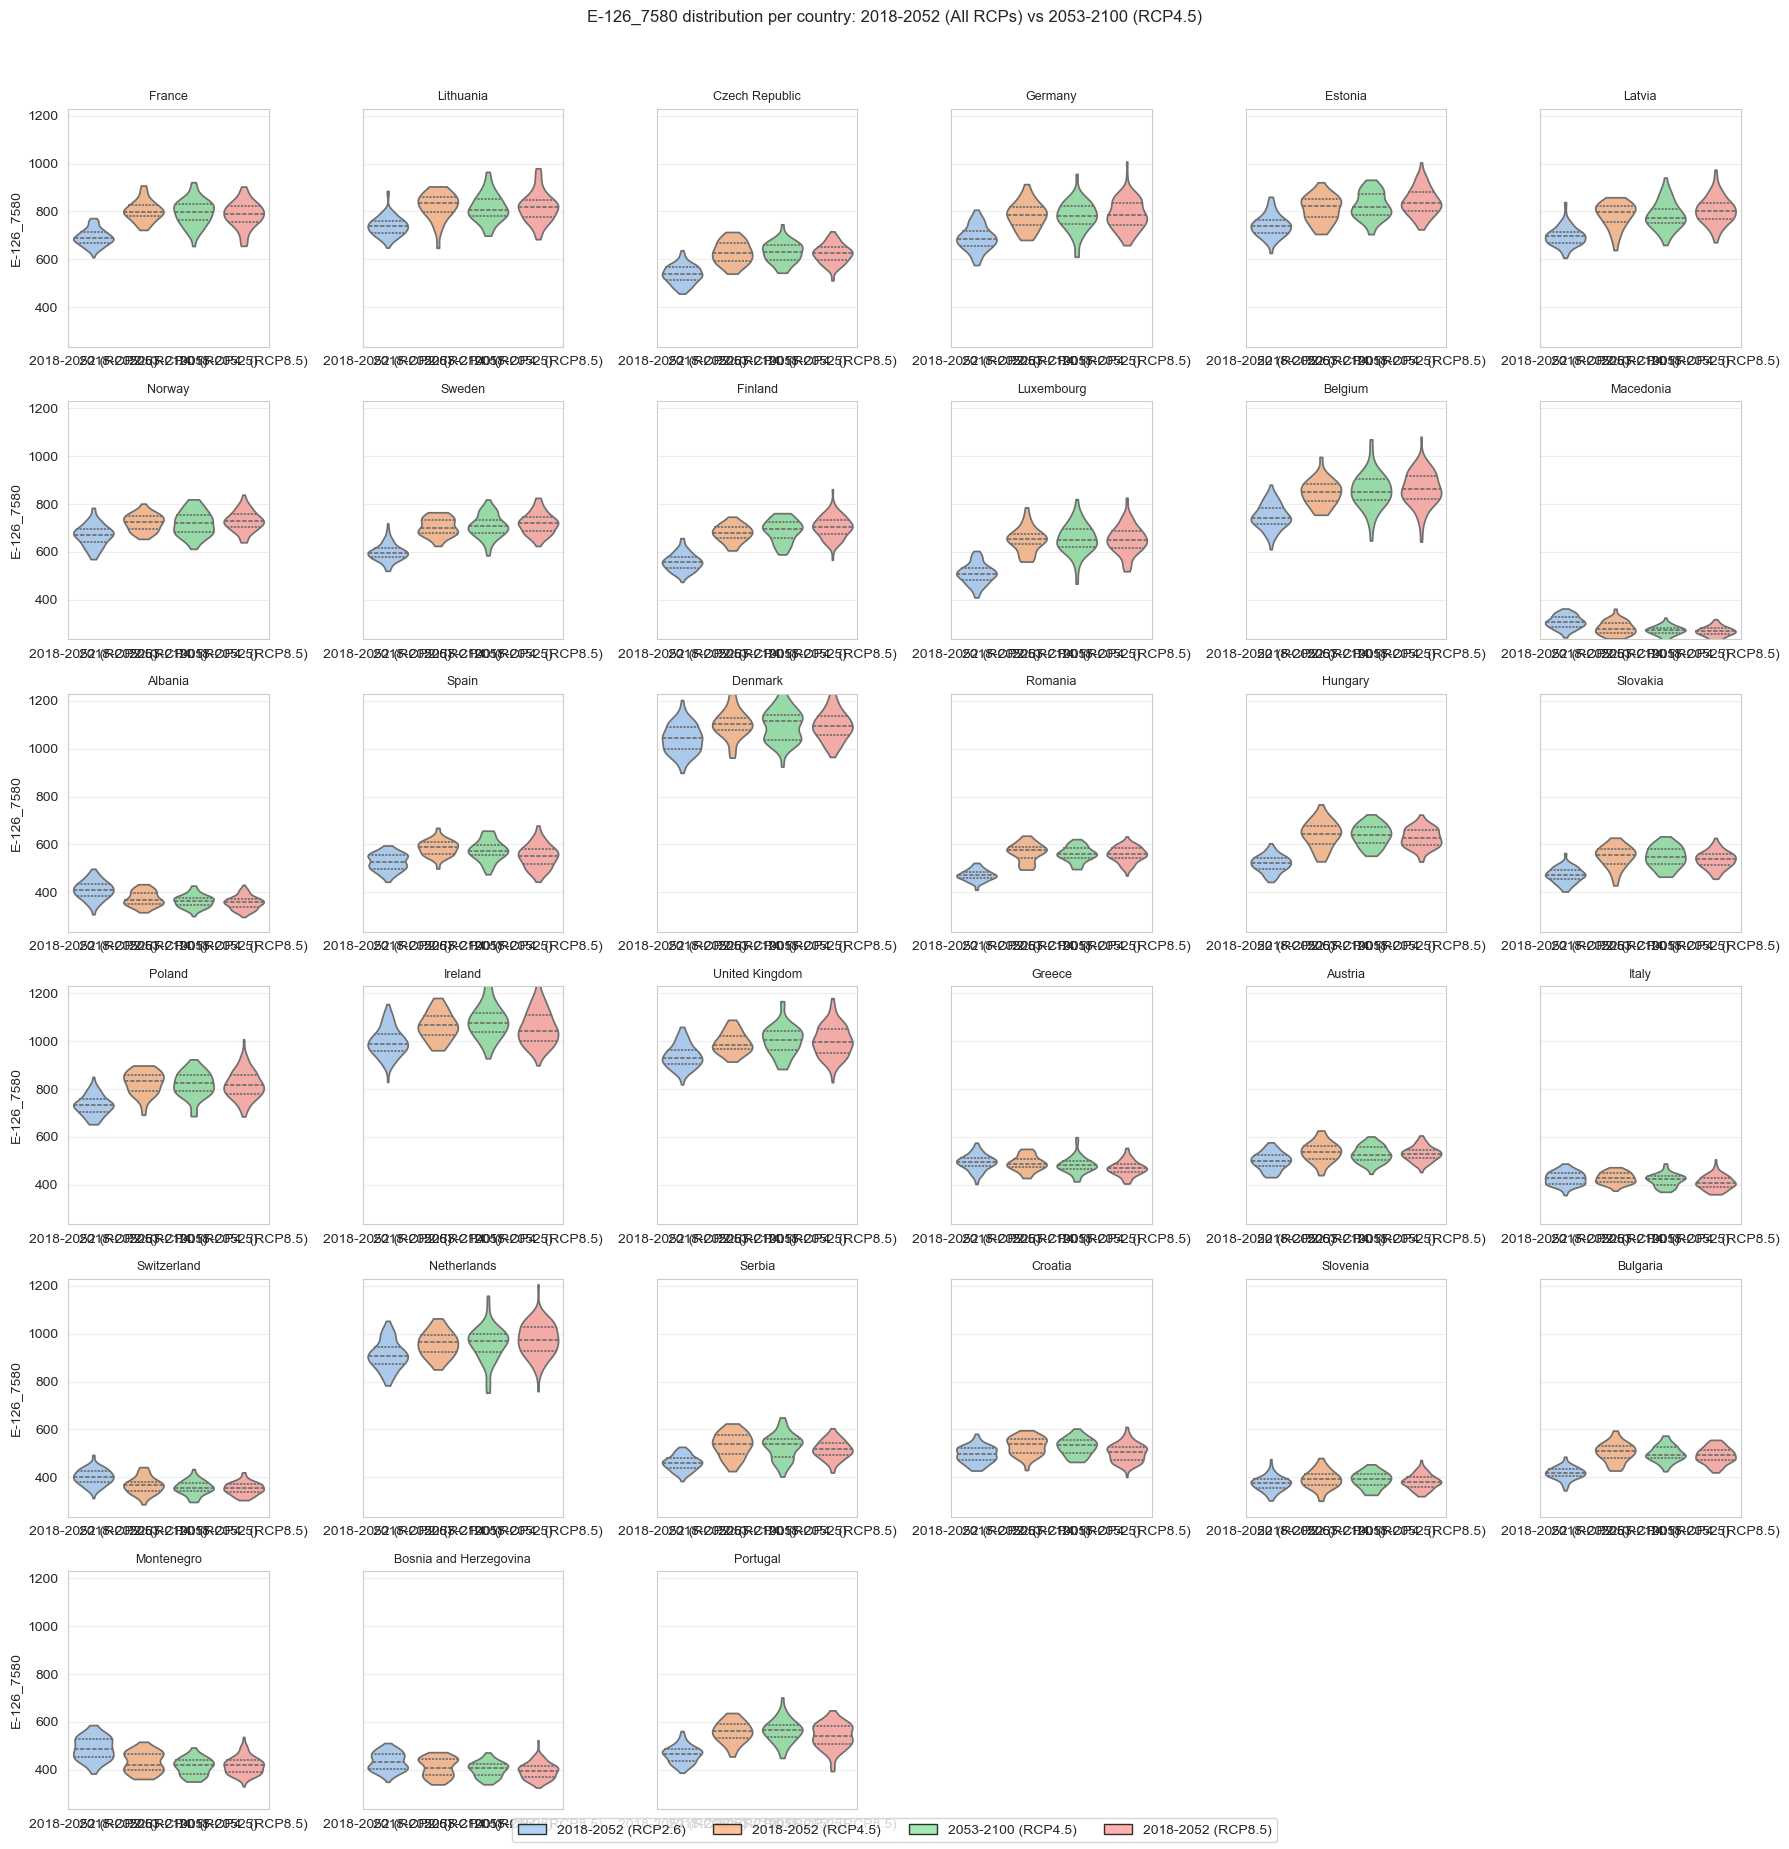

In [52]:
from matplotlib.patches import Patch

# compare datasets[1] periods to the combined full period of datasets[0] + datasets[1]
ds0_annual = datasets[0].resample(time="YE").sum(dim="time")
ds1_annual = datasets[1].resample(time="YE").sum(dim="time")
ds2_annual = datasets[2].resample(time="YE").sum(dim="time")

# convert to dataframes and drop NaNs
df0 = ds0_annual[var].to_dataframe().reset_index().dropna(subset=[var])
df1 = ds1_annual[var].to_dataframe().reset_index().dropna(subset=[var])
df2 = ds2_annual[var].to_dataframe().reset_index().dropna(subset=[var])

# slices from datasets[1]
df1_mid = df1[df1["time"].between("2018-01-01", "2052-12-31")].copy()
df1_mid["period"] = "2018-2052"
df1_late = df1[df1["time"].between("2053-01-01", "2100-12-31")].copy()
df1_late["period"] = "2053-2100"

# combined dataframe for plotting
combined_df = pd.concat([df0, df1_mid, df1_late, df2], ignore_index=True)

# plotting setup
countries_plot = list(df0["country"].unique())
n = len(countries_plot)
ncols = 6
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows), sharey=True)
axes = axes.flatten()

# robust y-limits
ymin, ymax = combined_df[var].quantile([0.001, 0.999]).values
labels = ["2018-2052 (RCP2.6)", "2018-2052 (RCP4.5)", "2053-2100 (RCP4.5)", "2018-2052 (RCP8.5)"]

# map dataframes to the desired labels (in the same order as `labels`)
dfs = [df0, df1_mid, df1_late, df2]

for i, country_name in enumerate(countries_plot):
    ax = axes[i]
    parts = []
    for d, lab in zip(dfs, labels):
        sub = d[d["country"] == country_name].copy()
        if sub.empty:
            continue
        sub["period_plot"] = lab
        parts.append(sub)

    if not parts:
        ax.set_visible(False)
        continue

    plot_df = pd.concat(parts, ignore_index=True)

    sns.violinplot(
        data=plot_df,
        x="period_plot",
        y=var,
        hue="period_plot",
        order=labels,
        cut=0,
        inner="quartile",
        ax=ax,
        palette="pastel",
        dodge=False,
    )

    # remove any legend created by the axis
    try:
        leg = ax.get_legend()
        if leg:
            leg.remove()
    except Exception:
        pass

    ax.set_title(country_name, fontsize=9)
    ax.set_xlabel("")
    if i % ncols != 0:
        ax.set_ylabel("")
    ax.set_ylim(ymin, ymax)

# remove unused axes
for j in range(len(countries_plot), len(axes)):
    fig.delaxes(axes[j])

# create a legend for the four labels
colors = sns.color_palette("pastel", n_colors=len(labels))
handles = [Patch(facecolor=colors[i], edgecolor="k", alpha=0.8, label=labels[i]) for i in range(len(labels))]
fig.legend(handles, labels, loc="lower center", ncol=len(labels))

plt.suptitle(f"{var} distribution per country: 2018-2052 (All RCPs) vs 2053-2100 (RCP4.5)", y=1.02)
plt.tight_layout()
plt.show()

## Load PV

In [11]:
path_pv = path_energy_europe / "pv"
path_pv_zarr = sorted(path_pv.glob(f"*/*{climate_scenario}*.zarr"))
paths_pv_nc = sorted(path_pv.glob(f"*/pv_agg_*{climate_scenario}*.nc"))
data_var_pv = list(xr.open_zarr(path_pv_zarr[0], chunks="auto").data_vars.keys())[0]

In [14]:
ds_pv = xr.concat(
    [xr.open_zarr(path, chunks="auto") for path in path_pv_zarr], dim="model"
)
ds_pv["model"] = [path.stem.split("pv_")[1] for path in path_pv_zarr]

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/core/indexing.py:1593: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]


In [44]:
ds_pv_agg = xr.concat(
    [xr.open_dataset(path, chunks="auto") for path in paths_pv_nc], dim="model"
)
ds_pv_agg["model"] = [path.stem.split("pv_agg_")[1] for path in paths_pv_nc]

## Load Wind

In [46]:
path_wind = path_energy_europe / "wind_power"
path_wind_zarr = sorted(
    path_wind.glob(f"*/*{climate_scenario}*{selected_turbine.replace('/', '_')}*.zarr")
)
paths_wind_agg_nc = sorted(
    path_wind.glob(
        f"*/wind_power_agg_*{climate_scenario}*{selected_turbine.replace('/', '_')}*.nc"
    )
)
paths_wind_offshore_nc = sorted(
    path_wind.glob(
        f"*/wind_power_offshore_*{climate_scenario}*{selected_turbine.replace('/', '_')}*.nc"
    )
)
data_var_wind = list(xr.open_zarr(path_wind_zarr[0], chunks="auto").data_vars.keys())[0]

In [47]:
ds_wind = xr.concat(
    [xr.open_zarr(path, chunks="auto") for path in path_wind_zarr], dim="model"
)
ds_wind["model"] = [
    path.stem.split("wind_power_")[1].split(f"_{selected_turbine.replace('/', '_')}")[0]
    for path in path_wind_zarr
]
ds_wind_agg = xr.concat(
    [xr.open_dataset(path, chunks="auto") for path in paths_wind_agg_nc], dim="model"
)
ds_wind_agg["model"] = [
    path.stem.split("wind_power_agg_")[1].split(
        f"_{selected_turbine.replace('/', '_')}"
    )[0]
    for path in paths_wind_agg_nc
]
ds_wind_offshore = xr.concat(
    [xr.open_dataset(path, chunks="auto") for path in paths_wind_offshore_nc],
    dim="model",
)
ds_wind_offshore["model"] = [
    path.stem.split("wind_power_offshore_")[1].split(
        f"_{selected_turbine.replace('/', '_')}"
    )[0]
    for path in paths_wind_offshore_nc
]

## Load hydropower

In [76]:
# Load hydropower
path_hydropower = path_energy_europe / "hydropower"
path_hydropower_zarr = sorted(path_hydropower.glob(f"*/*{climate_scenario}*.zarr"))
ds_hydropower = sel_extent(xr.concat(
    [
        xr.open_zarr(path, chunks="auto").convert_calendar("standard", align_on="year").sortby("lat", ascending=True)
        for path in path_hydropower_zarr
    ],
    dim="model",
), extent=extent)
ds_hydropower["lat"] = ds_pv["lat"]
ds_hydropower["lon"] = ds_pv["lon"]
ds_hydropower["model"] = [
    path.stem.split("hydropower_")[1] for path in path_hydropower_zarr
]

## Load demand

In [51]:
path_demand = path_energy_europe / "demand"
paths_demand_zarr = sorted(path_demand.glob(f"*{climate_scenario}.zarr"))

In [52]:
ds_cdd_hdd = sel_extent(xr.concat(
    [
        xr.open_zarr(path, chunks="auto").drop_duplicates(dim="time")
        for path in paths_demand_zarr
    ],
    dim="model",
), extent=extent)
ds_cdd_hdd["model"] = [path.stem for path in paths_demand_zarr]

In [53]:
da_worldpop_coarse = process_population_data(
    sel_extent(
        rxr.open_rasterio(
            Path(paths["path_data_processed"]) / "pop" / "ppp_2020_1km_Aggregated.tif"
        ).rename({"x": "lon", "y": "lat"}),
        extent=extent_pop,
    ),
    sel_extent(xr.open_zarr(paths_demand_zarr[0], chunks="auto"), extent=extent),
    coarsen=True,
)

countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_countries_worldpop = countries.mask(da_worldpop_coarse, flag="names")
da_worldpop_coarse = normalize_population_data(
    da_worldpop_coarse, mask_countries_worldpop
).where(da_worldpop_coarse > 0, np.nan)

## Analysis

In [11]:
mean_ref = sel_extent(
    xr.open_dataset(path_data_processed / "energy" / "mean_reference_period.nc").sel(
        model=valid_models
    ),
    extent=extent,
)
mean_mid_century = sel_extent(
    xr.open_dataset(path_data_processed / "energy" / "mean_mid_century.nc").sel(
        model=valid_models
    ),
    extent=extent,
)

In [12]:
# Apply the mask to all variables in mean_ref
for var in ["pv", "HDD", "CDD"]:
    mean_ref[var] = apply_land_mask(mean_ref[var])

# Repeat for mean_mid_century if needed:
for var in ["pv", "HDD", "CDD"]:
    mean_mid_century[var] = apply_land_mask(mean_mid_century[var])

### Visual inspection per model

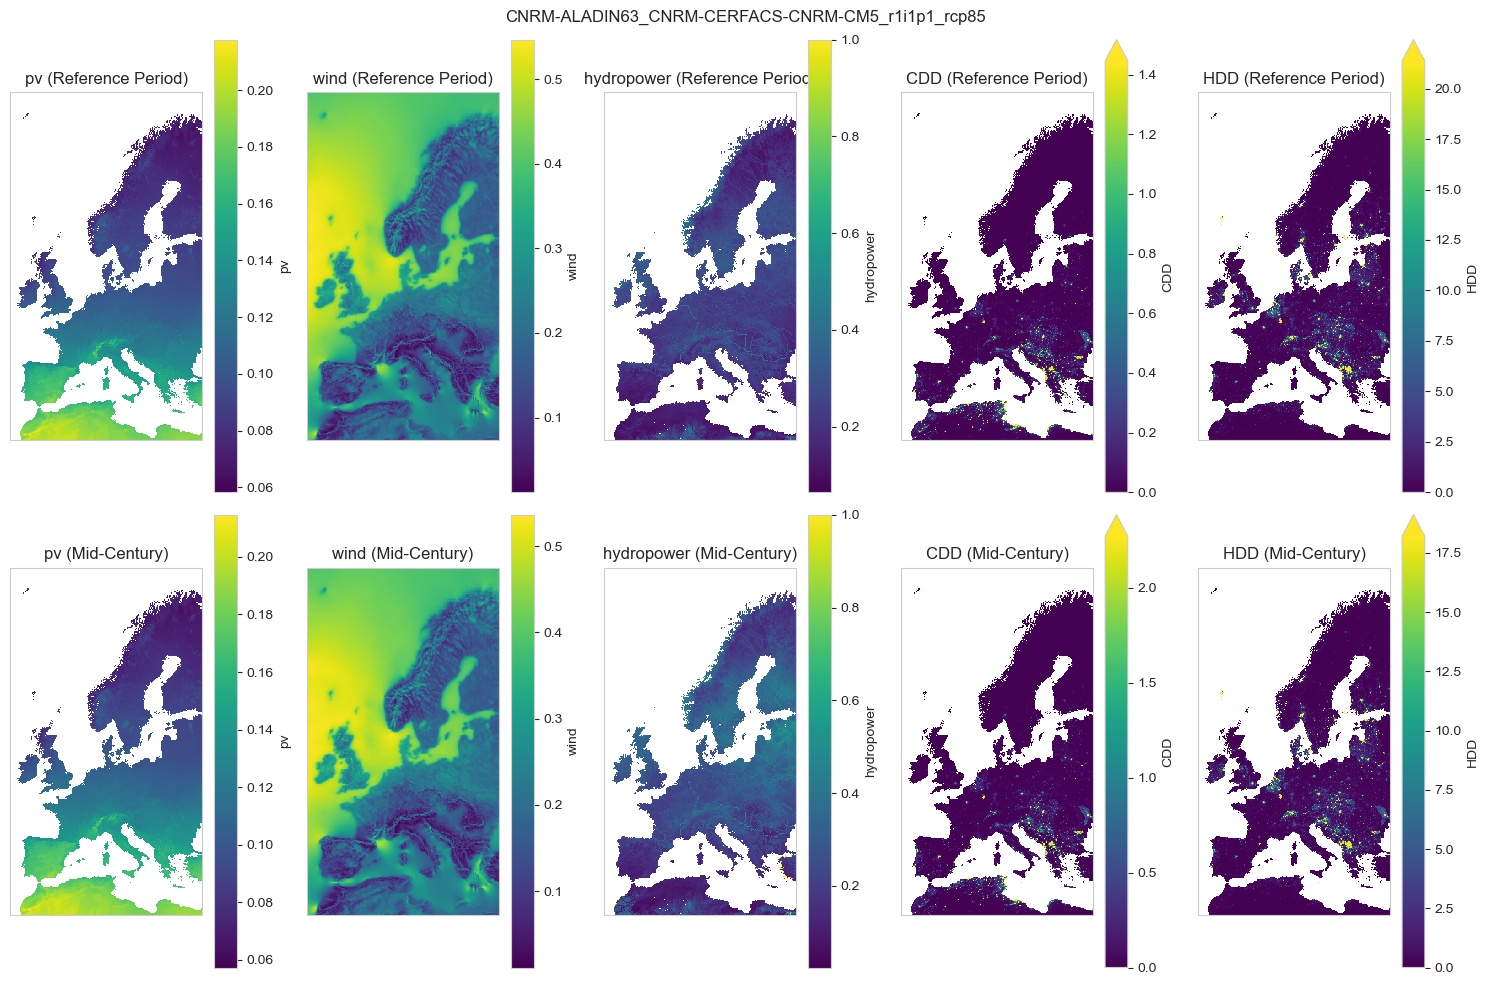

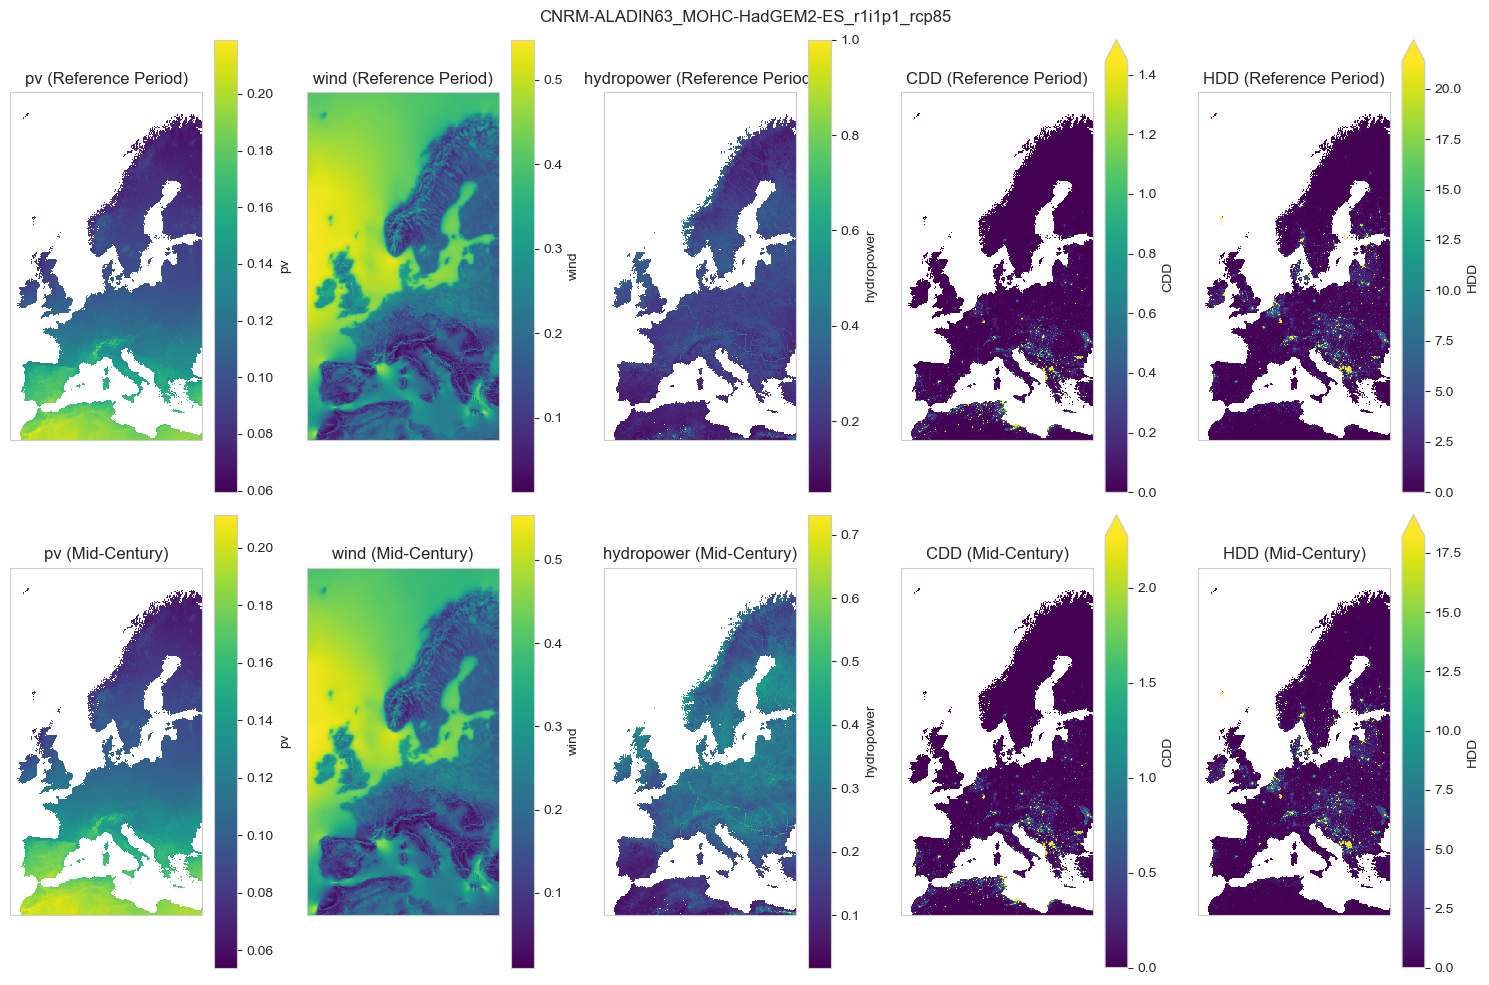

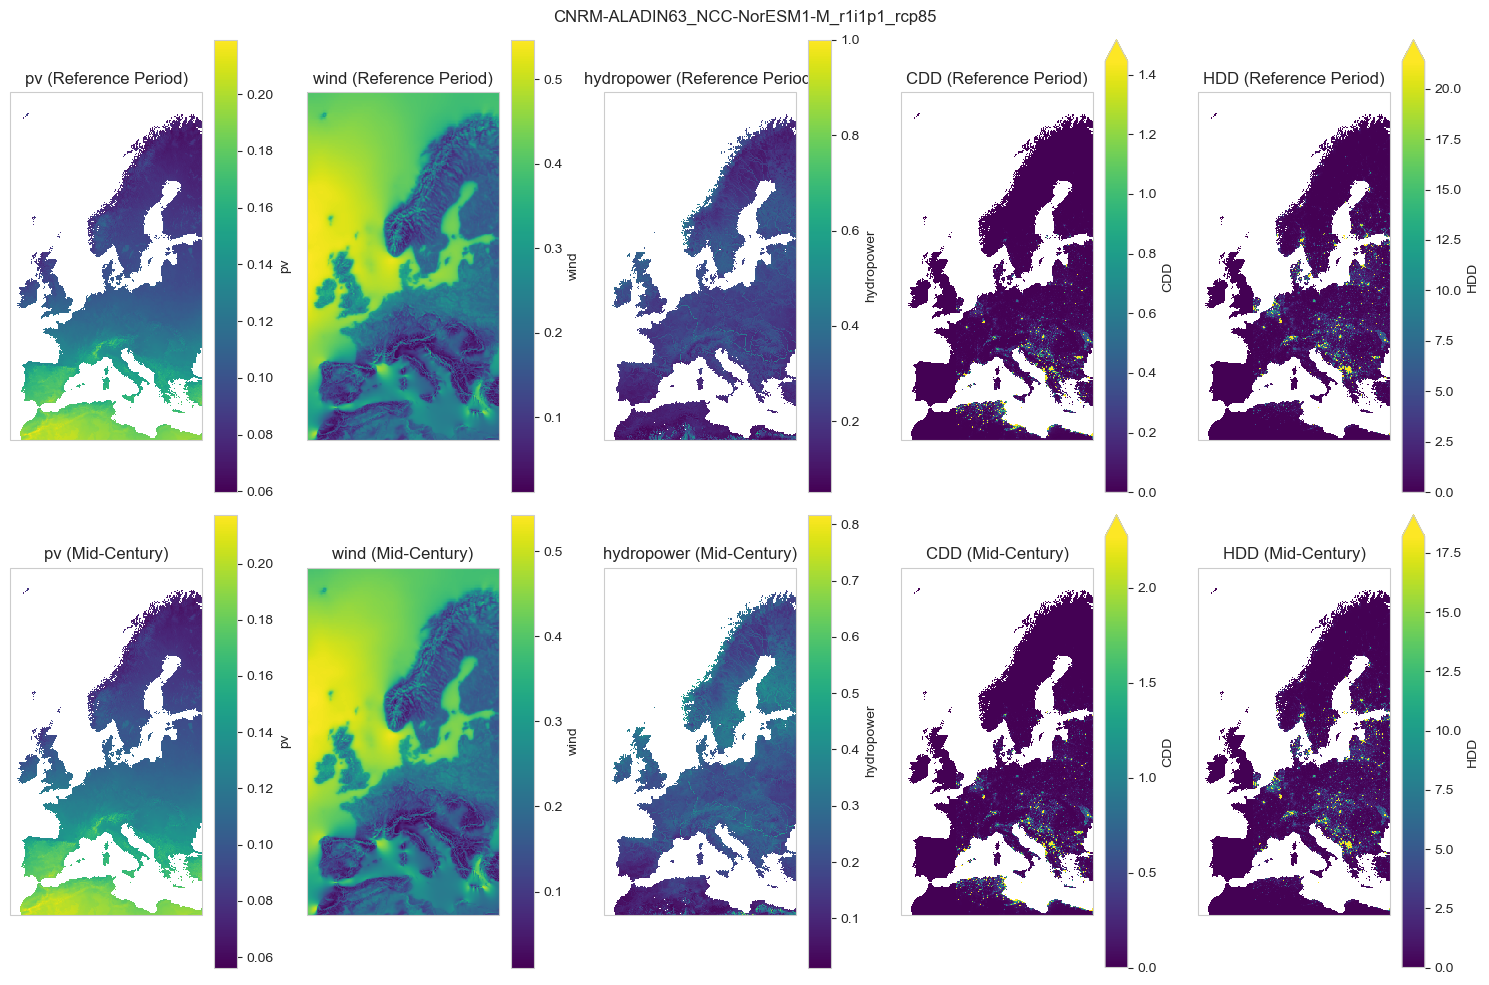

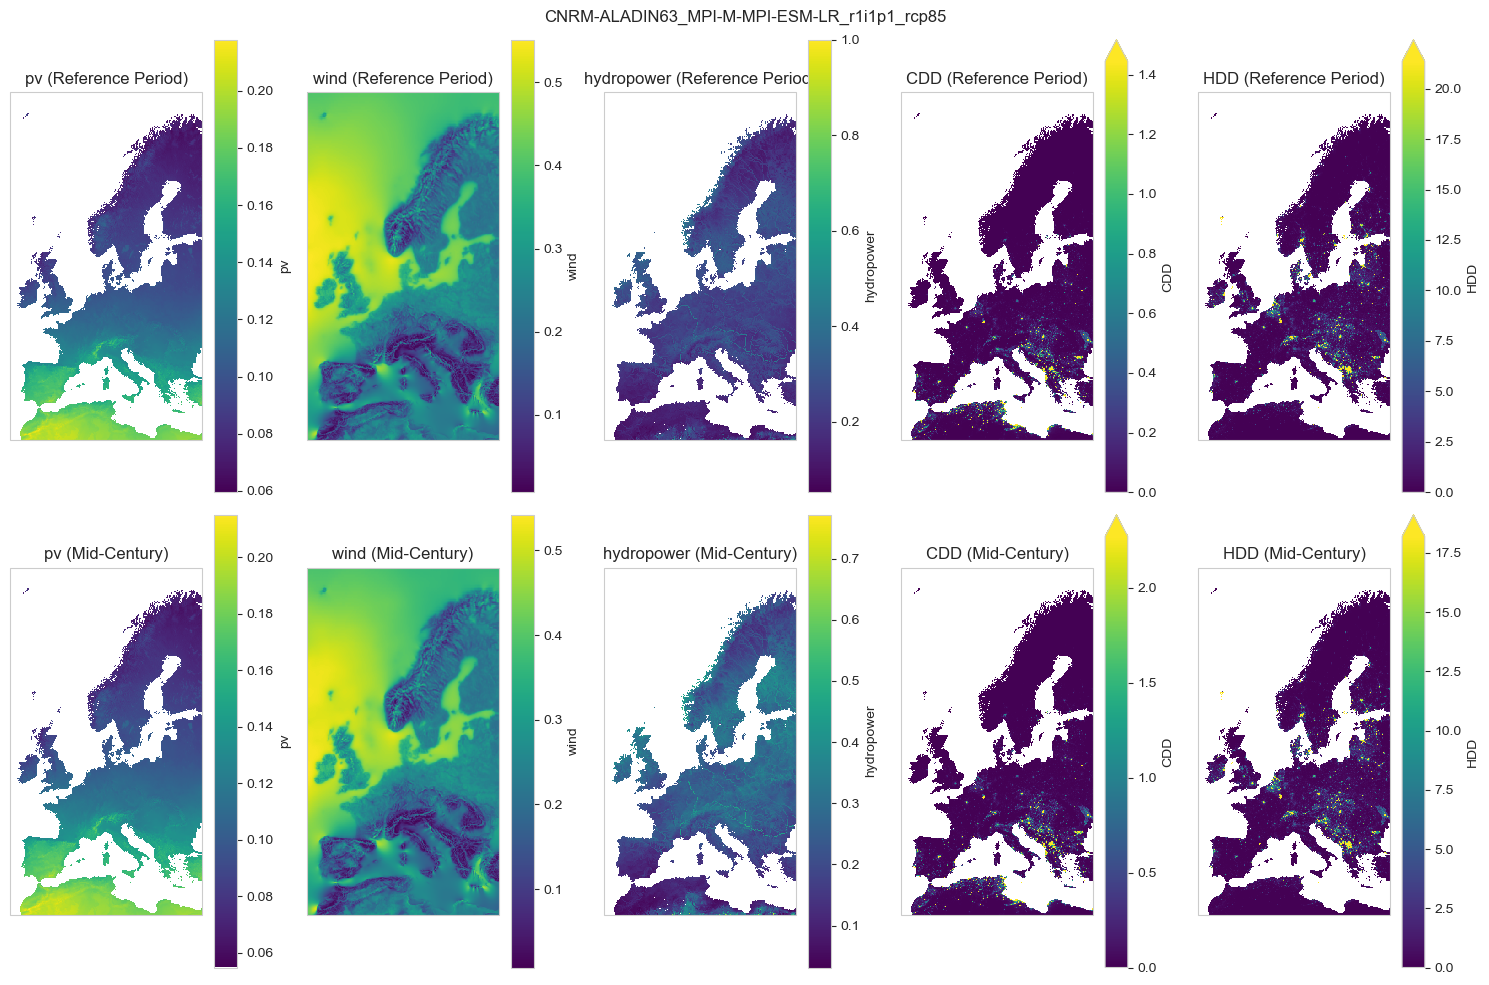

In [13]:
for model in mean_ref.model.values:
    fig, ax = plt.subplots(
        2,
        len(mean_ref.data_vars.keys()),
        figsize=(15, 10),
        subplot_kw={
            "projection": ccrs.Mercator(
                central_longitude=10.0, min_latitude=30.0, max_latitude=75.0
            )
        },
    )
    for i, var in enumerate(mean_ref.data_vars.keys()):
        mean_ref.sel(model=model).data_vars[var].plot(
            ax=ax[0, i],
            transform=ccrs.PlateCarree(),
            vmax=mean_ref[var].quantile(0.99) if var in ["HDD", "CDD"] else None,
        )
        ax[0, i].set_title(var + " (Reference Period)")
    for i, var in enumerate(mean_mid_century.data_vars.keys()):
        mean_mid_century.sel(model=model).data_vars[var].plot(
            ax=ax[1, i],
            transform=ccrs.PlateCarree(),
            vmax=mean_mid_century[var].quantile(0.99)
            if var in ["HDD", "CDD"]
            else None,
        )
        ax[1, i].set_title(var + " (Mid-Century)")
    plt.suptitle(model)
    plt.tight_layout()
    plt.show()

### Ensemble mean

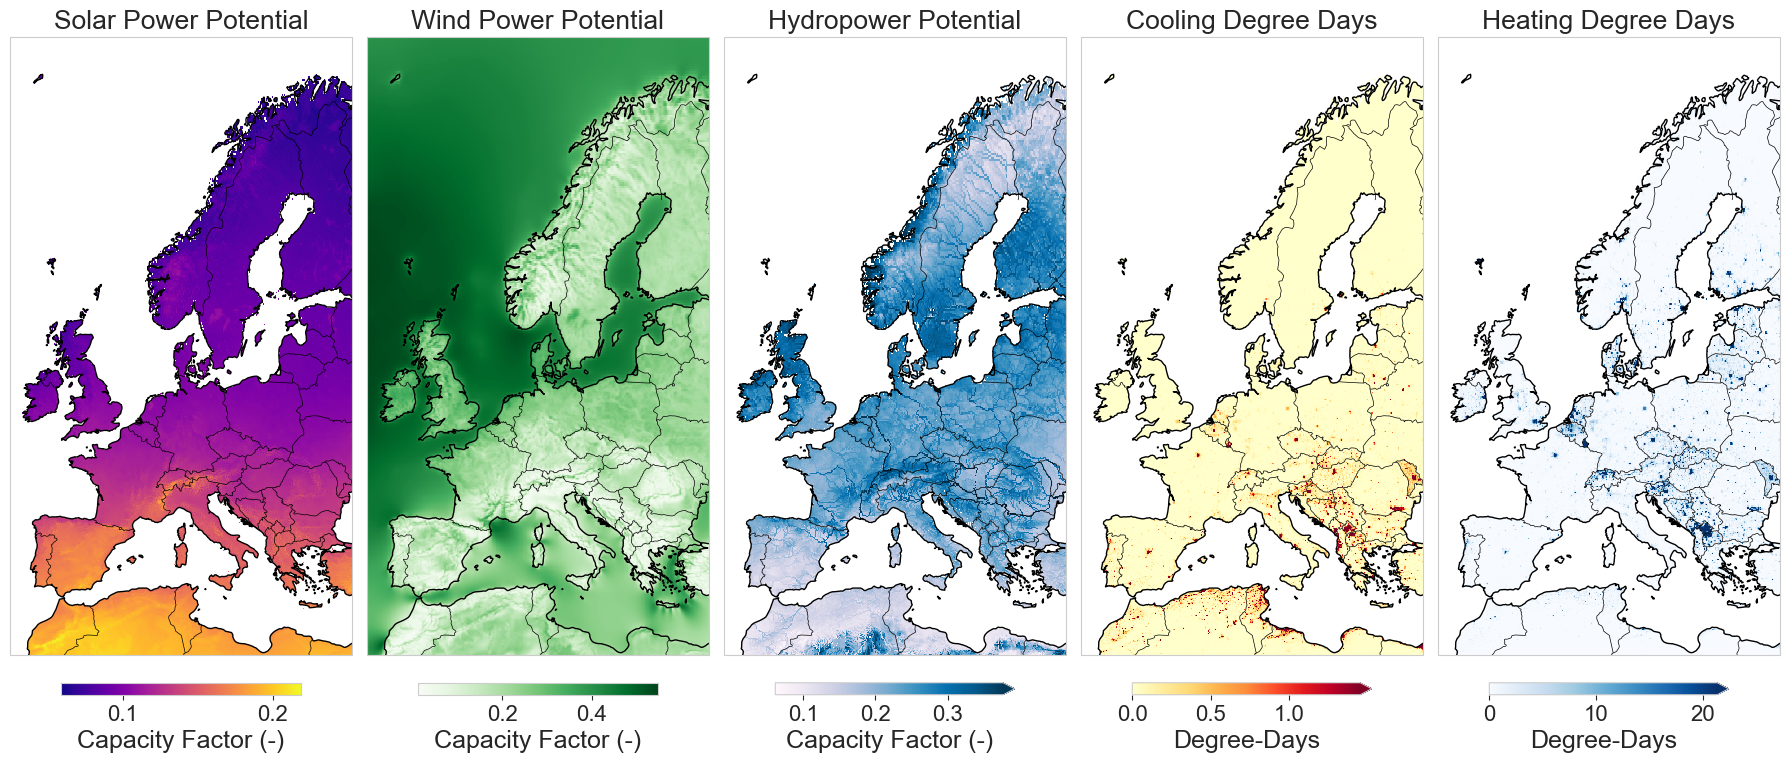

In [33]:
plot_ensemble_mean(mean_ref, figsize=(18, 9.5), country_border_width=0.5, title=None, path_savefig=path_figs / "energy" / "mean_ref.png")

### Ensemble mean change

/home/yhaddad/ClimateScenarios4Energy-CH/notebooks/conversion_energy/../../src/results/analysis.py:120: RuntimeWarning: Mean of empty slice
  lambda x: np.sum(np.sign(x) == np.sign(np.nanmean(x))),


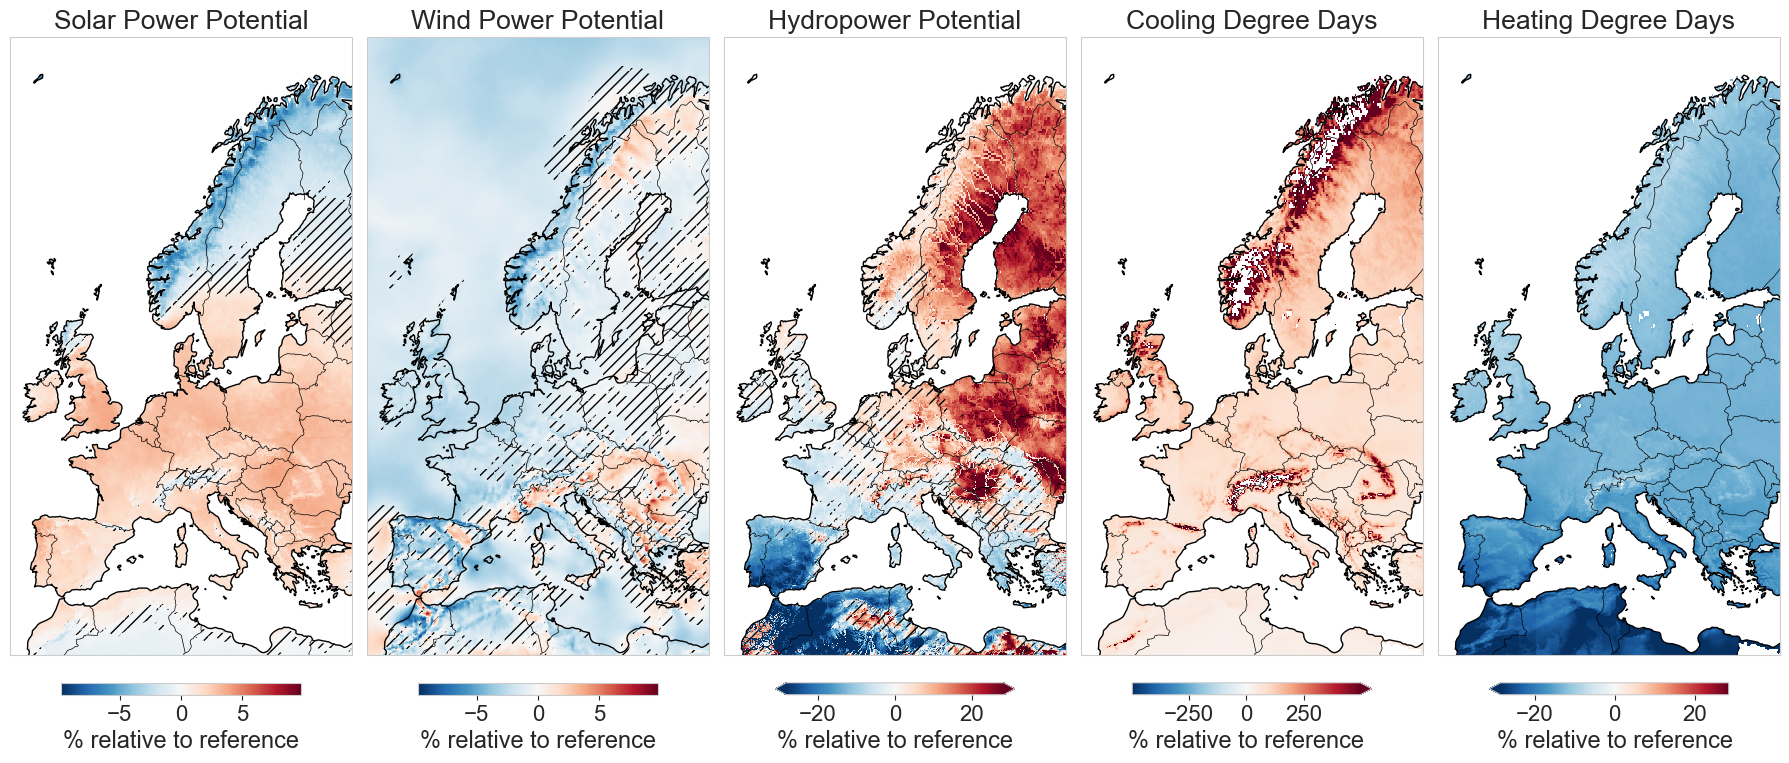

In [34]:
plot_ensemble_mean_percentage_change(mean_ref, mean_mid_century, figsize=(18, 9.5), title=None, path_savefig=path_figs / "energy" / "mean_change_mid_century.png")

# Switzerland

In [16]:
selected_turbine_ch = ch_turbines[0]
selected_pv_tilt_azimuth_ch = "tilt_35_azimuth_S"

In [17]:
ds_orog_cnrm_ch = sel_extent(
    xr.open_dataset(
        sorted(
            (path_data_temporary / "cordex_processed").glob("CNRM*/regridded/fx/*.nc")
        )[0]
    ),
    EXTENT_CH,
)

## Load data

In [ ]:
path_pv_ch = path_energy_ch / "pv"
path_pv_ch_zarr = sorted(path_pv_ch.glob(f"*{climate_scenario}*.zarr"))

ds_pv_ch = xr.concat(
    [
        xr.open_zarr(path, chunks="auto")[[selected_pv_tilt_azimuth_ch]]
        for path in path_pv_ch_zarr
    ],
    dim="model",
)
ds_pv_ch["model"] = [path.stem.split("pv_")[1] for path in path_pv_ch_zarr]
ds_pv_ch = ds_pv_ch.sel(model=valid_models)
data_var_pv_ch = list(ds_pv_ch.data_vars.keys())[0]

In [ ]:
path_wind_ch = path_energy_ch / "wind_power"
path_wind_ch_zarr = sorted(path_wind_ch.glob(f"*{climate_scenario}*.zarr"))

ds_wind_ch = xr.concat(
    [
        xr.open_zarr(path, chunks="auto")[[selected_turbine_ch.replace("/", "_")]]
        for path in path_wind_ch_zarr
    ],
    dim="model",
)
ds_wind_ch["model"] = [path.stem.split("wind_power_")[1] for path in path_wind_ch_zarr]
data_var_wind_ch = list(ds_wind_ch.data_vars.keys())[0]

In [ ]:
path_demand = path_energy_europe / "demand"
paths_demand_zarr = sorted(path_demand.glob(f"*{climate_scenario}.zarr"))
ds_cdd_hdd = sel_extent(
    xr.concat(
        [
            xr.open_zarr(path, chunks="auto").drop_duplicates(dim="time")
            for path in paths_demand_zarr
        ],
        dim="model",
    ),
    extent=EXTENT_CH,
)
ds_cdd_hdd["model"] = [path.stem for path in paths_demand_zarr]

[PosixPath('/net/exo/landclim/yhaddad/clim2energy-ch/energy/europe/demand/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85.zarr'), PosixPath('/net/exo/landclim/yhaddad/clim2energy-ch/energy/europe/demand/CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1_rcp85.zarr'), PosixPath('/net/exo/landclim/yhaddad/clim2energy-ch/energy/europe/demand/CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85.zarr')]


In [126]:
gdf_regions_ch = gpd.read_file(
    path_data_processed / "maps" / "regions_ch" / "PRODREG.shp"
).to_crs("EPSG:4326")
regions_ch = regionmask.from_geopandas(gdf_regions_ch, names="ProdregN_3")
regions_ch_mask = regions_ch.mask(ds_orog_cnrm_ch.orog)

## Analysis

In [18]:
mean_ref_ch = sel_extent(
    xr.open_dataset(path_data_processed / "energy" / "mean_reference_period_ch.nc").sel(
        model=valid_models
    ),
    extent=EXTENT_CH,
)
mean_ref_ch = mean_ref_ch[["pv", "wind", "hydropower", "CDD", "HDD"]]
mean_mid_century_ch = sel_extent(
    xr.open_dataset(path_data_processed / "energy" / "mean_mid_century_ch.nc").sel(
        model=valid_models
    ),
    extent=EXTENT_CH,
)
mean_mid_century_ch = mean_mid_century_ch[["pv", "wind", "hydropower", "CDD", "HDD"]]

In [19]:
# Apply the mask to all variables in mean_ref
for var in ["pv", "hydropower", "HDD", "CDD"]:
    if var in mean_ref_ch.data_vars:
        mean_ref_ch[var] = apply_land_mask(mean_ref_ch[var])

# Repeat for mean_mid_century if needed:
for var in ["pv", "hydropower", "HDD", "CDD"]:
    if var in mean_mid_century_ch.data_vars:
        mean_mid_century_ch[var] = apply_land_mask(mean_mid_century_ch[var])

In [20]:
regional_stats_seasonal = xr.open_dataset(
    path_data_processed / "energy" / "ch" / "statistics" / "regional_stats_seasonal.nc"
).sel(model=valid_models)
regional_stats_yearly = xr.open_dataset(
    path_data_processed / "energy" / "ch" / "statistics" / "regional_stats_yearly.nc"
).sel(model=valid_models)
regional_stats_yearly["mask"] = ["Swiss " + r for r in regional_stats_yearly.mask.values]

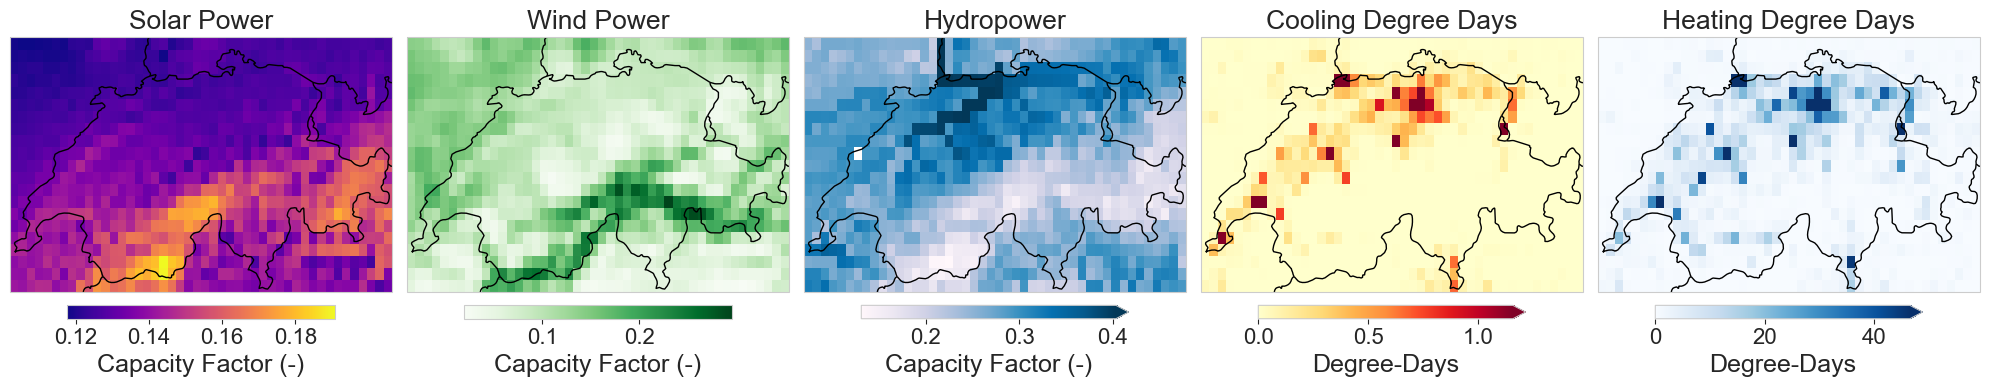

In [21]:
plot_ensemble_mean(mean_ref_ch, figsize=(20, 5), country_border_width=1,title=None, path_savefig=path_figs / "energy" / "mean_ref_ch.png")

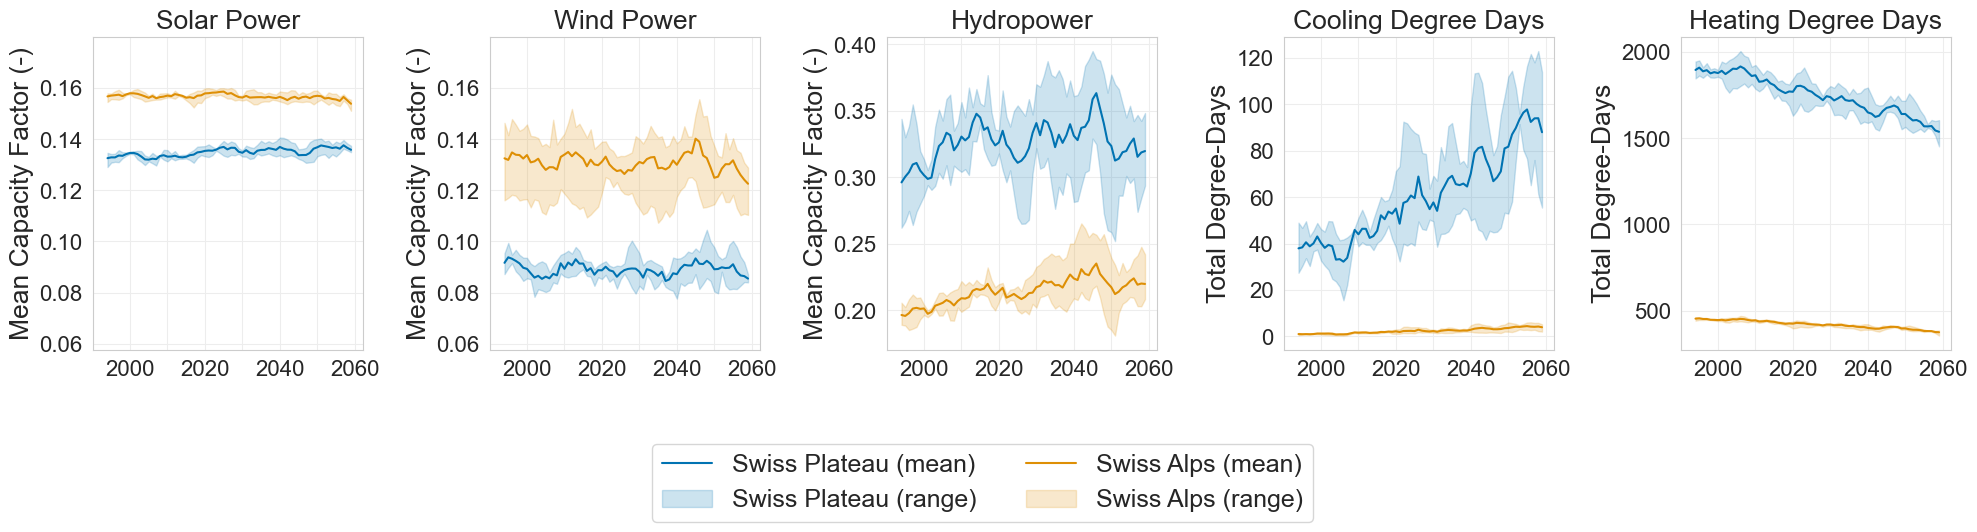

In [32]:
plot_yearly_timeseries_ensemble(
    regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], MID_CENTURY_PERIOD[1])),
    ["Swiss Plateau", "Swiss Alps"],
    figsize=(20, 4),
    title=None,
    path_savefig=path_figs / "energy" / "yearly_timeseries_ensemble.png"
)